# Chapitre 14 - Exercices 14.18 à 14.21

Ce notebook traite quatre exercices liés à l'**analyse en composantes indépendantes**
(ICA) et au **clustering spectral** :

- **14.18** : densités gaussiennes « inclinées » pénalisées et conditions de moments ;
- **14.19** : invariance du terme gaussien de la log-vraisemblance par rotation ;
- **14.20** : l'algorithme du point fixe de FastICA vu comme une méthode de Newton ;
- **14.21** : noyau du laplacien d'un graphe et composantes connexes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch14_non_supervise_complements as nsc
set_style()

## Exercice 14.18 : Moments de la densité estimée dans ProDenICA

**Énoncé (reformulé).** Dans l'approche directe de l'ICA (section 14.7.4), on estime la
densité d'une source sous la forme $f = \varphi\,e^{g}$ (gaussienne « inclinée »,
éq. (14.89)), en maximisant la log-vraisemblance régularisée (éq. (14.92)) :
$$\frac1N\sum_{i=1}^N\big[\log\varphi(s_i) + g(s_i)\big] - \int\varphi(t)e^{g(t)}\,dt
- \lambda\int\{g'''(t)\}^2\,dt.$$
La solution $\hat g$ est une spline de lissage quartique, que l'on écrit
$\hat g = \hat q + \hat q_\perp$ où $q(s) = \theta_0 + \theta_1 s + \theta_2 s^2$ est
quadratique (dans le noyau de la pénalité). En examinant les conditions de
stationnarité en $\theta_0, \theta_1, \theta_2$, montrer que $\hat f = \varphi e^{\hat g}$
est une densité, de moyenne nulle et de variance 1. Si l'on utilisait plutôt une pénalité
sur la dérivée seconde, $\int\{g''(t)\}^2dt$, quelle modification simple permettrait de
conserver ces trois conditions de moments ?

### Contexte et notations

- $\varphi(t) = e^{-t^2/2}/\sqrt{2\pi}$ est la densité gaussienne standard.
- Les $s_i = a^Tx_i$ sont les projections des données **blanchies** sur une direction
  unitaire $a$ : les $x_i$ sont centrés et de covariance empirique $I$, donc
  $$\frac1N\sum_i s_i = a^T\bar x = 0,\qquad
  \frac1N\sum_i s_i^2 = a^T\Big(\frac1N\sum_ix_ix_i^T\Big)a = a^Ta = 1.$$
- Le terme $-\int\varphi e^g$ remplace la contrainte « $\int f = 1$ » (on verra qu'il
  l'impose automatiquement à l'optimum).
- Le **noyau de la pénalité** $\int (g''')^2$ est l'ensemble des fonctions de pénalité
  nulle : $g''' = 0$, c'est-à-dire les polynômes de degré $\le 2$.

### Conditions de stationnarité

Notons $F(g)$ le critère. Pour toute fonction $h$ et tout réel $\varepsilon$, si $\hat g$
est un maximum alors $\varepsilon \mapsto F(\hat g + \varepsilon h)$ est maximal en
$\varepsilon = 0$, donc sa dérivée y est nulle. Calculons cette dérivée terme à terme
(en dérivant sous l'intégrale) :

- $\frac{d}{d\varepsilon}\frac1N\sum_i[\log\varphi(s_i) + \hat g(s_i) + \varepsilon h(s_i)]
  = \frac1N\sum_i h(s_i)$ ;
- $\frac{d}{d\varepsilon}\int\varphi e^{\hat g + \varepsilon h}\Big|_{\varepsilon=0}
  = \int\varphi(t)e^{\hat g(t)}h(t)\,dt = \int\hat f(t)h(t)\,dt$ ;
- $\frac{d}{d\varepsilon}\lambda\int(\hat g''' + \varepsilon h''')^2\Big|_{\varepsilon=0}
  = 2\lambda\int\hat g'''h'''$.

Choisissons $h(s) = s^k$ pour $k = 0, 1, 2$ : c'est exactement faire varier le
coefficient $\theta_k$ de la partie quadratique $\hat q$. Comme $h''' = 0$, **le terme de
pénalité ne contribue pas**, et la condition de stationnarité devient
$$\int t^k\,\hat f(t)\,dt = \frac1N\sum_{i=1}^N s_i^k,\qquad k = 0, 1, 2.$$
Les trois premiers moments de $\hat f$ coïncident avec les moments empiriques.

On en déduit :

- $k = 0$ : $\int\hat f = 1$ ; comme $\hat f > 0$, **$\hat f$ est une densité** ;
- $k = 1$ : $\int t\hat f(t)\,dt = \frac1N\sum_is_i = 0$ : **moyenne nulle** ;
- $k = 2$ : $\int t^2\hat f(t)\,dt = \frac1N\sum_is_i^2 = 1$, donc la variance vaut
  $1 - 0^2 = 1$.

> **Intuition.** Les paramètres non pénalisés jouent le rôle de multiplicateurs de
> Lagrange : la pénalité ne « freine » pas les directions de son noyau, donc l'estimateur
> ajuste exactement les statistiques correspondantes (comme une régression de Poisson avec
> constante reproduit le total observé).

### Avec une pénalité sur la dérivée seconde

Avec $\int (g'')^2$, le noyau de la pénalité ne contient plus que les fonctions
**affines** $\theta_0 + \theta_1 s$. Le raisonnement précédent donne encore $\int\hat f = 1$
et une moyenne nulle, mais plus la variance : pour $h(s) = s^2$, $h'' = 2 \ne 0$ et le
terme $4\lambda\int\hat g''$ subsiste.

**Modification simple :** sortir le terme quadratique de la pénalité. On écrit
$g(s) = \theta_2 s^2 + r(s)$ avec $\theta_2$ libre et l'on pénalise seulement
$\lambda\int\{r''(t)\}^2dt$. Le noyau de la pénalité redevient l'ensemble des
quadratiques, et la condition $k = 2$ est rétablie.

Optimiser d'abord en $\theta_2$ revient à pénaliser
$\min_{\theta}\int(g'' - 2\theta)^2 = \int\big(g'' - \overline{g''}\big)^2$, où
$\overline{g''}$ est la moyenne de $g''$ sur l'intervalle : on pénalise les **variations**
de la dérivée seconde autour de sa moyenne, ce qui laisse libres les paraboles.
(Une autre option serait d'imposer la contrainte de variance par un multiplicateur de
Lagrange, ce qui revient au même : ajouter un terme $\theta_2 s^2$ non pénalisé.)

### Vérification numérique

Nous utilisons la version discrétisée (14.94) du livre : une grille fine de cases de
largeur $\Delta$, les proportions $y^*_\ell$ d'observations par case, et la fonction $g$
représentée par ses valeurs $g_\ell$ sur la grille. Les dérivées sont remplacées par des
**différences finies** ; la pénalité devient $\lambda\,g^TD_k^TD_kg$ où $D_k$ est la
matrice des différences d'ordre $k$. Le noyau de $D_3$ est exactement l'ensemble des
suites quadratiques : la même preuve donne alors
$$\Delta\sum_\ell \hat f(s^*_\ell)\,(s^*_\ell)^k = \sum_\ell y^*_\ell\,(s^*_\ell)^k,\quad k=0,1,2.$$
La maximisation est faite par la méthode de Newton (fonction `tilted_gaussian_fit`).

In [2]:
rng = np.random.RandomState(0)
s_raw = rng.uniform(-1, 1, 1000)
s_src = (s_raw - s_raw.mean()) / s_raw.std()          # source blanchie
print("moyenne = %.2e, moment d'ordre 2 = %.6f" % (s_src.mean(), (s_src ** 2).mean()))

moyenne = 4.00e-17, moment d'ordre 2 = 1.000000


In [3]:
fits = {
    "pénalité g''' ": nsc.tilted_gaussian_fit(s_src, lam=50.0, order=3),
    "pénalité g''  ": nsc.tilted_gaussian_fit(s_src, lam=50.0, order=2),
    "g'' recentrée ": nsc.tilted_gaussian_fit(s_src, lam=50.0, order=2, center_penalty=True),
}
print("%-15s %10s %12s %12s" % ("", "intégrale", "moyenne", "variance"))
for name, fit in fits.items():
    t, f, d = fit["grid"], fit["f"], fit["delta"]
    m0 = (f * d).sum()
    m1 = (t * f * d).sum() / m0
    m2 = (t ** 2 * f * d).sum() / m0 - m1 ** 2
    print("%-15s %10.6f %12.2e %12.6f" % (name, m0, m1, m2))

                 intégrale      moyenne     variance
pénalité g'''     1.000000     1.05e-04     0.999807
pénalité g''      1.000000     1.05e-04     1.024443
g'' recentrée     1.000000     1.05e-04     0.999807


Les moments de référence (calculés sur les données discrétisées) :

In [4]:
fit = fits["pénalité g''' "]
t, y = fit["grid"], fit["y"]
print("données binnées : moyenne = %.2e, variance = %.6f"
      % ((t * y).sum(), (t ** 2 * y).sum() - (t * y).sum() ** 2))

données binnées : moyenne = 1.05e-04, variance = 0.999807


Avec la pénalité d'ordre 3, l'intégrale vaut 1 et les deux moments coïncident avec ceux
des données discrétisées (aux erreurs d'arrondi près ; la petite différence avec les
moments exacts $0$ et $1$ vient seulement de la discrétisation en cases). Avec la
pénalité d'ordre 2, l'intégrale et la moyenne restent exactes mais la variance **ne
vaut plus 1** : le terme $s^2$ est pénalisé, et rien n'oblige plus $\hat f$ à reproduire
le moment d'ordre 2. La version recentrée rétablit la variance exacte.

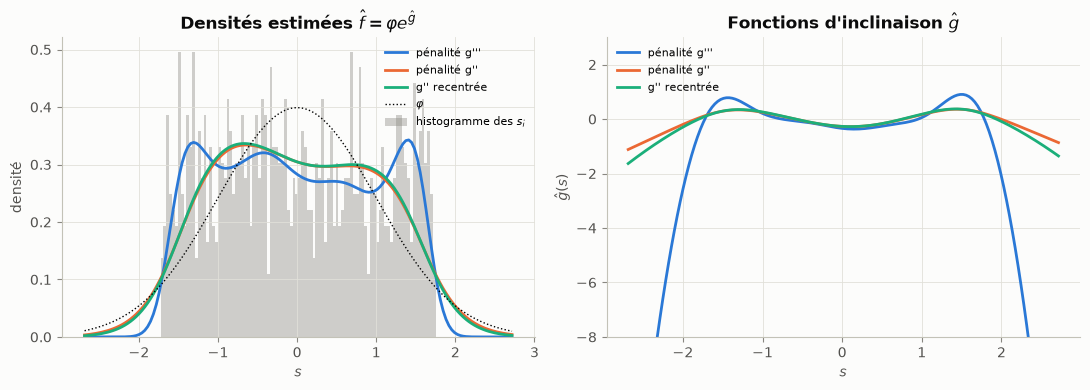

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(t, y / fit["delta"], width=fit["delta"], color=GRAY, alpha=0.4,
       label="histogramme des $s_i$")
for (name, ft), col in zip(fits.items(), COLORS):
    ax.plot(ft["grid"], ft["f"], color=col, label=name.strip())
ax.plot(t, np.exp(-t ** 2 / 2) / np.sqrt(2 * np.pi), color="k", ls=":", lw=1,
        label=r"$\varphi$")
ax.set_xlabel("$s$"); ax.set_ylabel("densité")
ax.set_title(r"Densités estimées $\hat f = \varphi e^{\hat g}$")
ax.legend(fontsize=8)
ax = axes[1]
for (name, ft), col in zip(fits.items(), COLORS):
    ax.plot(ft["grid"], ft["g"], color=col, label=name.strip())
ax.set_xlabel("$s$"); ax.set_ylabel(r"$\hat g(s)$")
ax.set_title(r"Fonctions d'inclinaison $\hat g$")
ax.set_ylim(-8, 3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()